# Machine Learning — Practical Session 1
## Python for Data Exploration and Preprocessing
**Institution:** National Higher School of Advanced Technologies  
**Academic Year:** 2026–2027 | First-Year Master's Degree  
**Course:** Machine Learning  

---

### Objectives
1. **Explore Tabular Data:** Inspect datasets, select features, manage deep copies, and create stratified train/test splits.
2. **Explore Text Data:** Read raw encoded text files and inspect structured text corpora using scikit-learn's 20 Newsgroups dataset.
3. **Handle Missing Values:** Detect missing value patterns, identify non-standard placeholder strings, and apply univariate imputation strategies while preventing data leakage.
4. **Feature Scaling, Binarization, and Encoding:** Compare column-wise feature scaling vs. row-wise normalization, apply binarization, and encode categorical data with ordinal, label, and one-hot encoders.
5. **Methodological Synthesis:** Answer core conceptual discussion questions regarding evaluation integrity, data leakage, and inductive biases.

## Setup and Library Imports
We import the foundational libraries specified for this practical session: `pandas`, `numpy`, `matplotlib`, `seaborn`, and `scikit-learn`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.model_selection import train_test_split
from sklearn.datasets import fetch_20newsgroups
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    MaxAbsScaler,
    RobustScaler,
    normalize,
    Binarizer,
    OrdinalEncoder,
    LabelEncoder,
    OneHotEncoder
)

# Plotting settings for clear visuals
%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11

print("Environment initialized successfully.")


Environment initialized successfully.


---
## Exercise 1 — Exploring a Tabular Dataset and Creating Data Splits

In this exercise, we explore the classic **Iris dataset** (`data/Iris_Dataset.csv`), examine its structural properties, select specific feature subsets, understand the importance of defensive copying, and perform a stratified train/test split.

### Step 1.1: Load the Dataset into DataFrame `D`

In [2]:
# Load the Iris dataset into a pandas DataFrame named D
iris_path = 'data/Iris_Dataset.csv'
D = pd.read_csv(iris_path)

# Display the first few rows
D.head()


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


### Step 1.2: Inspect the Dataset
We inspect the dataset using five core pandas attributes and methods: `info()`, `describe()`, `shape`, `columns`, and `head()`. Each gives a distinct perspective on the data.

In [3]:
print("--- 1. Dataset Shape ---")
print(f"Shape: {D.shape} -> {D.shape[0]} rows and {D.shape[1]} columns\n")

print("--- 2. Dataset Columns ---")
print(D.columns.tolist(), "\n")

print("--- 3. Dataset Info ---")
D.info()

print("\n--- 4. Summary Statistics (describe) ---")
display(D.describe())

print("--- 5. First 5 Rows (head) ---")
display(D.head())


--- 1. Dataset Shape ---
Shape: (150, 5) -> 150 rows and 5 columns

--- 2. Dataset Columns ---
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species'] 

--- 3. Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB

--- 4. Summary Statistics (describe) ---


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


--- 5. First 5 Rows (head) ---


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


#### Explanation of Inspection Outputs

1. **`shape`:** Returns the tuple `(150, 5)`. This tells us the dataset contains exactly 150 observations (rows) across 5 attributes (columns).
2. **`columns`:** Returns the column labels: `sepal_length`, `sepal_width`, `petal_length`, `petal_width`, and `species`. The first four are physical flower measurements (in centimeters), and `species` is the categorical target.
3. **`info()`:** Provides memory footprint, column non-null counts, and data types (`float64` for the 4 continuous measurements, and `object`/string for `species`). It shows 150 non-null entries for every column, indicating no missing values in this dataset.
4. **`describe()`:** Computes summary statistics for numeric features:
   - `count`: 150 valid measurements per feature.
   - `mean` and `std`: Quantifies central location and dispersion (e.g., `sepal_length` has a mean of 5.84 cm with std of 0.83 cm).
   - `min`, `25%`, `50%` (median), `75%`, `max`: Five-number summary revealing feature distributions and spread (e.g., `petal_width` ranges from 0.10 cm to 2.50 cm).
5. **`head()`:** Displays the first 5 records, allowing verification of column alignment, formatting, and scale.

### Step 1.3 & 1.4: Feature Selection
We extract two specific features — `sepal_length` and `petal_width` — into a separate DataFrame, and display the first 20 observations.

In [4]:
# Select sepal_length and petal_width into a new DataFrame
df_selected = D[['sepal_length', 'petal_width']]

# Display the first 20 observations
df_selected.head(20)


,sepal_length,petal_width
0,5.1,0.2
1,4.9,0.2
2,4.7,0.2
3,4.6,0.2
4,5.0,0.2
5,5.4,0.4
6,4.6,0.3
7,5.0,0.2
8,4.4,0.2
9,4.9,0.1


### Step 1.5: Defensive Copying
We create a copy of the original DataFrame and discuss why making explicit copies is critical when experimenting with data preprocessing.

In [5]:
# Create a deep copy of the original DataFrame
D_copy = D.copy()

# Verify that D_copy is an independent object in memory
print(f"Original D id: {id(D)}, Copy D_copy id: {id(D_copy)}")
print(f"Are they distinct objects? {D is not D_copy}")


Original D id: 2304714846768, Copy D_copy id: 2304715077776
Are they distinct objects? True


#### Why copies are useful in preprocessing experiments
In Python and pandas, simple assignments like `df2 = df` do not duplicate data; they create another reference pointing to the exact same underlying object in memory. Any transformation, imputation, or filtering applied to `df2` will silently mutate `df`, potentially triggering `SettingWithCopyWarning` and corrupting the raw data.

Using `.copy()` creates an independent deep copy of the DataFrame and its index:
1. **Preserving Ground Truth:** It keeps the raw, untouched dataset intact as a benchmark for comparison.
2. **Safe Experimentation:** Practitioners can test multiple preprocessing pipelines (e.g., different scalers, imputation rules, or feature transformations) without reloading files or compounding mutations.
3. **Preventing Side-Effects:** Functions and pipeline components can transform their local copy without unintended side-effects on other parts of the workflow.

### Step 1.6 & 1.7: Stratified Train/Test Split
We now partition the dataset into training (80%) and testing (20%) sets using `train_test_split()`.
- **Input features ($X$):** The four continuous measurement columns (`sepal_length`, `sepal_width`, `petal_length`, `petal_width`). Note that this uses all four features, clearly distinct from the two-feature subset in Step 1.3.
- **Target ($y$):** The categorical `species` column.
- **Stratification:** We specify `stratify=y` to ensure identical class proportions in both splits.
- **Reproducibility:** We set `random_state=42` to guarantee reproducible results.

In [6]:
# Define features X (all 4 measurement columns) and target y (species)
feature_cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
X = D[feature_cols]
y = D['species']

# Split into 80% train and 20% test, with stratification on y
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")


X_train shape: (120, 4)
X_test shape:  (30, 4)
y_train shape: (120,)
y_test shape:  (30,)


### Step 1.8: Verify Sizes and Class Proportions
We verify that the 80/20 proportion is satisfied and inspect class counts and percentages in both subsets.

In [7]:
# Calculate counts and proportions for training set
train_counts = y_train.value_counts()
train_props = y_train.value_counts(normalize=True) * 100

# Calculate counts and proportions for test set
test_counts = y_test.value_counts()
test_props = y_test.value_counts(normalize=True) * 100

# Combine into a summary DataFrame
split_summary = pd.DataFrame({
    'Train Count': train_counts,
    'Train %': train_props.round(2),
    'Test Count': test_counts,
    'Test %': test_props.round(2)
})

print(f"Total training observations: {len(y_train)} ({len(y_train)/len(D):.1%})")
print(f"Total test observations:     {len(y_test)} ({len(y_test)/len(D):.1%})")
print("\nClass balance summary:")
display(split_summary)


Total training observations: 120 (80.0%)
Total test observations:     30 (20.0%)

Class balance summary:


,Train Count,Train %,Test Count,Test %
species,,,,
Iris-setosa,40,33.33,10,33.33
Iris-virginica,40,33.33,10,33.33
Iris-versicolor,40,33.33,10,33.33


### Discussion — Exercise 1

> **Question:** *Why should the test set be kept separate until the final evaluation? What could happen if information from the test set influences preprocessing or model selection?*

**Answer:**
1. **Purpose of the Test Set:** In supervised machine learning, the ultimate goal is to build models that generalize accurately to unseen, future data. The test set acts as an uncorrupted proxy for that future data; its sole purpose is to provide an unbiased estimate of the model's true generalization performance.
2. **The Danger of Data Leakage (Information Contamination):** If test data is involved in preprocessing (such as computing global mean/standard deviation for standardization, calculating medians for missing value imputation, or selecting features based on correlation with the target), information from the test set "leaks" into the training workflow.
3. **Consequences:** 
   - When test statistics leak into training, the model's parameters and evaluation metrics are computed on data the model has already effectively seen.
   - This results in **overly optimistic evaluation scores** during cross-validation and testing.
   - When the model is subsequently deployed in production on truly novel data, performance degrades drastically because the model was fitted with leaked knowledge that will not exist in live environments.

---
## Exercise 2 — Exploring Text Data

Text data presents distinct structural properties compared to tabular data. Here we examine two text sources:
1. A raw, delimited local text file (`data/txt_file.txt`).
2. Scikit-learn's standard text classification corpus: the **20 Newsgroups** dataset.

### Step 2.1 & 2.2: Read and Display `data/txt_file.txt`
We open `data/txt_file.txt` with UTF-8 encoding, iterate over its lines, and display each line after stripping only the trailing newline character.

In [8]:
txt_path = 'data/txt_file.txt'

print(f"Reading '{txt_path}' with UTF-8 encoding:\n")
with open(txt_path, mode='r', encoding='utf-8') as f:
    for line_num, line in enumerate(f, start=1):
        # Remove only the trailing newline characters
        cleaned_line = line.rstrip('\r\n')
        # Display non-empty lines
        if cleaned_line:
            print(f"Line {line_num}: {cleaned_line}")


Reading 'data/txt_file.txt' with UTF-8 encoding:

Line 1: 0.50,0.20,0.84,0.01,c1
Line 2: 0.10,0.10,0.40,0.02,c2
Line 3: 0.15,0.10,0.45,0.03,c2
Line 4: 0.22,0.20,0.90,0.01,c1
Line 5: 0.25,0.20,0.87,0.01,c1
Line 6: 0.10,0.10,0.38,0.02,c2


*Observation:* Although stored with a `.txt` extension, `data/txt_file.txt` is structured as comma-separated numerical features followed by a discrete class identifier (`c1` or `c2`). This illustrates that text files frequently serve as raw containers for delimited tabular records in practical data ingestion pipelines.

### Step 2.3: Load the 20 Newsgroups Dataset
We load the training subset (`subset='train'`) of scikit-learn's 20 Newsgroups dataset using `fetch_20newsgroups()`. We include robust error handling to gracefully report network issues if internet access is unavailable.

In [9]:
try:
    print("Attempting to load the 20 Newsgroups training dataset...")
    newsgroups_train = fetch_20newsgroups(subset='train', shuffle=True, random_state=42)
    print("Dataset loaded successfully.")
except Exception as e:
    newsgroups_train = None
    print(f"Error fetching 20 Newsgroups dataset: {type(e).__name__} - {e}")
    print("Please verify your internet connection or download the dataset archive manually.")


Attempting to load the 20 Newsgroups training dataset...


Dataset loaded successfully.


### Step 2.4: Document Count, Labels, and Dimensionality
We inspect the dataset dimensions: the number of documents, target labels, and unique classes.

In [10]:
if newsgroups_train is not None:
    num_documents = len(newsgroups_train.data)
    num_targets = len(newsgroups_train.target)
    num_classes = len(newsgroups_train.target_names)
    
    print(f"Number of documents in training set: {num_documents}")
    print(f"Number of target labels:              {num_targets}")
    print(f"Number of distinct classes/topics:    {num_classes}")


Number of documents in training set: 11314
Number of target labels:              11314
Number of distinct classes/topics:    20


#### Meaning of these dimensions
- **Number of documents (`11,314`):** The training set contains 11,314 individual Usenet newsgroup posts. In NLP, this corresponds to the corpus size ($N$), where each document is an uncurated natural-language string of variable length.
- **Number of target labels (`11,314`):** A 1D NumPy array of integers matching each document to its ground-truth topic category.
- **Number of classes (`20`):** The taxonomy consists of 20 distinct discussion categories, spanning technology, politics, religion, sports, and science.

### Step 2.5: Inspect the First Document and its Target Label

In [11]:
if newsgroups_train is not None:
    first_doc = newsgroups_train.data[0]
    first_target = newsgroups_train.target[0]
    first_class_name = newsgroups_train.target_names[first_target]
    
    print(f"--- First Document Target ---")
    print(f"Numeric Target Code: {first_target}")
    print(f"Class Name:          {first_class_name}")
    print(f"Document Length:     {len(first_doc)} characters, {len(first_doc.split())} words\n")
    print("--- First Document Content (preview) ---")
    print(first_doc[:500] + "\n... [truncated] ...")


--- First Document Target ---
Numeric Target Code: 7
Class Name:          rec.autos
Document Length:     721 characters, 123 words

--- First Document Content (preview) ---
From: lerxst@wam.umd.edu (where's my thing)
Subject: WHAT car is this!?
Nntp-Posting-Host: rac3.wam.umd.edu
Organization: University of Maryland, College Park
Lines: 15

 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a m
... [truncated] ...


### Step 2.6: Available Class Names and Mapping
We display all 20 class names and demonstrate how numeric target indices map directly to human-readable topics.

In [12]:
if newsgroups_train is not None:
    class_mapping = pd.DataFrame({
        'Class Index': range(len(newsgroups_train.target_names)),
        'Topic Name': newsgroups_train.target_names
    })
    
    print("20 Newsgroups Class Mapping:")
    display(class_mapping)


20 Newsgroups Class Mapping:


,Class Index,Topic Name
0,0,alt.atheism
1,1,comp.graphics
2,2,comp.os.ms-windows.misc
3,3,comp.sys.ibm.pc.hardware
4,4,comp.sys.mac.hardware
5,5,comp.windows.x
6,6,misc.forsale
7,7,rec.autos
8,8,rec.motorcycles
9,9,rec.sport.baseball


#### How numeric target values correspond to class names
Scikit-learn represents multiclass targets as contiguous integers: $y \in \{0, 1, \dots, K-1\}$.  
The list `target_names` stores class strings sorted by their integer code:
$$\text{Class Name} = \text{target\_names}[y_i]$$
For instance, if $y_0 = 7$, indexing `newsgroups_train.target_names[7]` yields `'rec.autos'`. This integer encoding is computationally efficient for loss functions and classification algorithms while remaining interpretable through the lookup table.

### Step 2.7: Optional Extension — Document Length and Word Frequencies
To explore the corpus further, we inspect document length distributions and the most frequent terms across the first 100 documents.

In [13]:
if newsgroups_train is not None:
    from collections import Counter
    import re
    
    # Calculate word counts across the training subset
    word_counts = [len(doc.split()) for doc in newsgroups_train.data]
    char_counts = [len(doc) for doc in newsgroups_train.data]
    
    length_df = pd.DataFrame({
        'Word Count': word_counts,
        'Character Count': char_counts
    })
    
    print("Document Length Summary Statistics:")
    display(length_df.describe().round(2))
    
    # Tokenize words from a subset of 100 documents to observe frequent terms
    tokens = []
    for doc in newsgroups_train.data[:100]:
        words = re.findall(r'\b[a-zA-Z]{3,}\b', doc.lower())
        tokens.extend(words)
    
    frequent_words = Counter(tokens).most_common(10)
    freq_df = pd.DataFrame(frequent_words, columns=['Term', 'Frequency'])
    print("\nTop 10 Most Frequent Words (Sample of 100 documents):")
    display(freq_df)


Document Length Summary Statistics:


,Word Count,Character Count
count,11314.00,11314.00
mean,287.47,1949.31
std,541.48,4159.98
min,14.00,125.00
25%,108.00,753.25
50%,176.00,1178.00
75%,293.00,1881.00
max,11821.00,75154.00



Top 10 Most Frequent Words (Sample of 100 documents):


,Term,Frequency
0,the,1373
1,and,560
2,that,327
3,for,247
4,you,199
5,from,194
6,edu,177
7,this,164
8,have,163
9,with,161


---
## Exercise 3 — Detecting and Handling Missing Values

Real-world datasets rarely arrive complete. In this exercise, we explore missing-value patterns in `data/employees.csv`, examine how non-standard placeholders mask missingness from automated tools, convert placeholders consistently, apply appropriate imputation strategies, and demonstrate the training-only fitting principle.

### Step 3.1: Load `data/employees.csv` and Inspect Structure

In [14]:
emp_path = 'data/employees.csv'
df_emp = pd.read_csv(emp_path)

print(f"Dataset Dimensions: {df_emp.shape[0]} rows, {df_emp.shape[1]} columns\n")
print("--- Column Data Types ---")
print(df_emp.dtypes, "\n")

print("--- First 5 Rows ---")
display(df_emp.head())


Dataset Dimensions: 1000 rows, 8 columns

--- Column Data Types ---
First Name               str
Gender                   str
Start Date               str
Last Login Time          str
Salary                 int64
Bonus %              float64
Senior Management     object
Team                     str
dtype: object 

--- First 5 Rows ---


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
0,Douglas,Male,8/6/1993,12:42 PM,97308,6.945,True,Marketing
1,Thomas,Male,3/31/1996,6:53 AM,61933,4.170,True,NaN
2,Maria,Female,4/23/1993,11:17 AM,130590,11.858,False,Finance
3,Jerry,Male,3/4/2005,1:00 PM,138705,9.340,True,Finance
4,Larry,Male,1/24/1998,4:47 PM,101004,1.389,True,Client Services


### Step 3.2: Count Missing Values per Column using `isna().sum()`

In [15]:
# Count missing values per column
missing_counts = df_emp.isna().sum()
missing_pct = (missing_counts / len(df_emp)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing %': missing_pct.round(2),
    'Data Type': df_emp.dtypes
})

display(missing_summary)


,Missing Count,Missing %,Data Type
First Name,67,6.7,str
Gender,145,14.5,str
Start Date,0,0.0,str
Last Login Time,0,0.0,str
Salary,0,0.0,int64
Bonus %,0,0.0,float64
Senior Management,67,6.7,object
Team,43,4.3,str


### Step 3.3: Visualize Missing-Value Patterns with a Seaborn Heatmap
A missingness heatmap provides an immediate visual diagnostic of whether missing values are distributed randomly or concentrated in specific columns/subgroups.

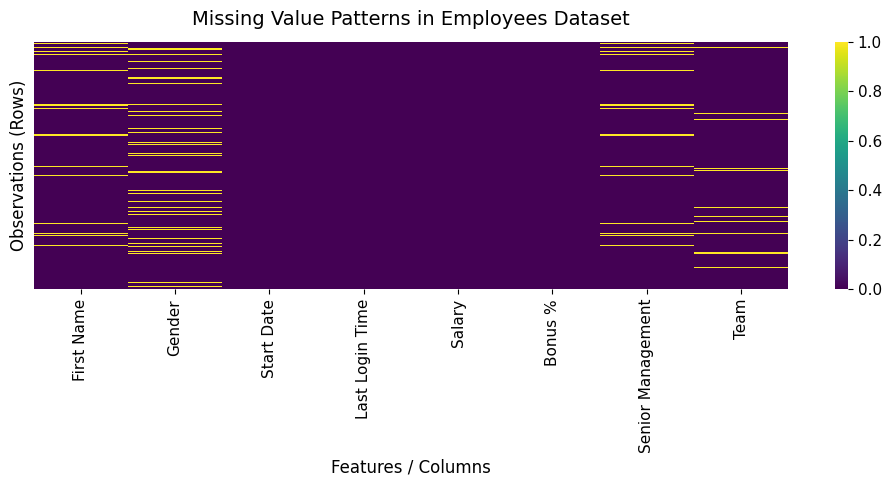

In [16]:
plt.figure(figsize=(10, 5))
sns.heatmap(
    df_emp.isna(),
    cbar=True,
    yticklabels=False,
    cmap='viridis'
)
plt.title('Missing Value Patterns in Employees Dataset', fontsize=14, pad=12)
plt.xlabel('Features / Columns', fontsize=12)
plt.ylabel('Observations (Rows)', fontsize=12)
plt.tight_layout()
plt.show()


### Step 3.4: Append a Synthetic Row with Custom Missing Markers
We create a copy of `df_emp` and append one synthetic row containing eight fields:
- `First Name`: `'-'` (non-standard text placeholder)
- `Gender`: `'na'` (lowercase text placeholder)
- `Start Date`: `'?'` (unknown date placeholder)
- `Last Login Time`: `'?'` (unknown time placeholder)
- `Salary`: `np.nan` (numeric missingness)
- `Bonus %`: `np.nan` (numeric missingness)
- `Senior Management`: `'unknown'` (categorical text placeholder)
- `Team`: `'?'` (unassigned department placeholder)

In [17]:
# Create a deep copy of the original DataFrame
df_emp_copy = df_emp.copy()

# Construct the synthetic row matching all 8 columns
synthetic_row = pd.DataFrame([{
    'First Name': '-',
    'Gender': 'na',
    'Start Date': '?',
    'Last Login Time': '?',
    'Salary': np.nan,
    'Bonus %': np.nan,
    'Senior Management': 'unknown',
    'Team': '?'
}])

# Append the synthetic row to the copied DataFrame
df_emp_copy = pd.concat([df_emp_copy, synthetic_row], ignore_index=True)

# Display the newly appended row
print("Appended Synthetic Row:")
display(df_emp_copy.tail(1))


Appended Synthetic Row:


,First Name,Gender,Start Date,Last Login Time,Salary,Bonus %,Senior Management,Team
1000,-,na,?,?,NaN,NaN,unknown,?


#### Explanation of Marker Choices
1. `First Name` (`'-'`) and `Gender` (`'na'`): Specified by the assignment to model legacy data entry shortcuts and non-standard notation.
2. `Start Date` and `Last Login Time` (`'?'`): Text markers signifying missing or unverified timestamps.
3. `Salary` and `Bonus %` (`np.nan`): Using standard IEEE 754 `NaN` maintains floating-point numerical types without converting numerical columns to generic Python objects.
4. `Senior Management` (`'unknown'`): Represents an indeterminate boolean state where managerial role is unconfirmed.
5. `Team` (`'?'`): Standard placeholder representing an unassigned departmental unit.

### Step 3.5: Recount Missing Values and Explain why `'-'` and `'na'` are Not Counted

In [18]:
# Recount missing values in the copy containing the synthetic row
recount_missing = df_emp_copy.isna().sum()

compare_counts = pd.DataFrame({
    'Original Missing': missing_counts,
    'After Appending Synthetic Row': recount_missing,
    'Difference': recount_missing - missing_counts
})

display(compare_counts)


,Original Missing,After Appending Synthetic Row,Difference
First Name,67,67,0
Gender,145,145,0
Start Date,0,0,0
Last Login Time,0,0,0
Salary,0,1,1
Bonus %,0,1,1
Senior Management,67,67,0
Team,43,43,0


#### Why `'-'` and `'na'` are NOT automatically treated as missing by pandas
- In pandas, `isna()` specifically checks for valid missing-value indicators: `np.nan` (IEEE 754 floating-point NaN), `None` (Python NoneType), or pandas-native `pd.NA`.
- The string `'-'` is a valid, single-character string object of length 1 (ASCII code 45).
- The string `'na'` is a valid, two-character lowercase string (ASCII codes 110, 97).
- Unless explicitly declared via the `na_values` parameter during `pd.read_csv()` (or converted post-hoc), pandas considers any arbitrary string as a legitimate, non-null categorical value. Consequently, `isna()` evaluates to `False` for both `'-'` and `'na'`, which risks corrupting downstream modeling if left unaddressed.

### Step 3.6: Consistent Conversion of Placeholders to `np.nan`
We define an explicit list of agreed placeholders (`'-'`, `'na'`, `'NA'`, `'?'`, `'unknown'`) and replace them with `np.nan` across the DataFrame using a consistent, exact-match rule.

In [19]:
# Define agreed placeholder strings
placeholders = ['-', 'na', 'NA', '?', 'unknown']

# Replace placeholders with np.nan using exact matching to avoid corrupting valid substrings
df_emp_cleaned = df_emp_copy.replace(placeholders, np.nan)

# Recount missing values to verify conversion
converted_missing = df_emp_cleaned.isna().sum()

compare_conversion = pd.DataFrame({
    'Before Replacement': recount_missing,
    'After Replacement (NaN)': converted_missing,
    'Converted Count': converted_missing - recount_missing
})

display(compare_conversion)


,Before Replacement,After Replacement (NaN),Converted Count
First Name,67,68,1
Gender,145,146,1
Start Date,0,1,1
Last Login Time,0,1,1
Salary,1,1,0
Bonus %,1,1,0
Senior Management,67,68,1
Team,43,44,1


### Step 3.7: Missing Value Imputation with `SimpleImputer`
We apply `sklearn.impute.SimpleImputer` with strategies tailored to column data types:
1. **Numerical Columns (`Salary`, `Bonus %`):** We use the **`median`** strategy. The median is robust to extreme values, skewness, and outliers, preserving the central tendency without distortion.
2. **Categorical Columns (`Gender`, `Senior Management`, `Team`):** We use the **`most_frequent`** (mode) strategy. Categorical variables lack arithmetic ordering, so replacing missing entries with the most common valid class is a standard univariate approach.
3. **Identifier Column (`First Name`):** We **do not impute** individual names with median or mode. Imputing personal names creates artificial identities (e.g., assigning hundreds of employees the name 'Marilyn'), corrupting entity integrity. Personal identifiers should be dropped from predictive modeling or assigned a distinct category like `'Unknown'`.
4. **Date/Time Columns (`Start Date`, `Last Login Time`):** Kept separate or filled with forward/backward fill in temporal workflows; not suited for simple arithmetic mean/median imputation.

In [20]:
# Define column groups
num_cols = ['Salary', 'Bonus %']
cat_cols = ['Gender', 'Senior Management', 'Team']

# Initialize imputers
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

# Create a copy for imputation results
df_imputed = df_emp_cleaned.copy()

# Impute numerical features
df_imputed[num_cols] = num_imputer.fit_transform(df_imputed[num_cols])

# Impute categorical features
df_imputed[cat_cols] = cat_imputer.fit_transform(df_imputed[cat_cols])

# Explicitly mark First Name identifier missingness as 'Unknown'
df_imputed['First Name'] = df_imputed['First Name'].fillna('Unknown')

# Check remaining missing values
print("Missing values after imputation:")
print(df_imputed[num_cols + cat_cols + ['First Name']].isna().sum())


Missing values after imputation:
Salary               0
Bonus %              0
Gender               0
Senior Management    0
Team                 0
First Name           0
dtype: int64


### Step 3.8: Before vs. After Imputation Comparison and Limitations

In [21]:
imputation_comparison = pd.DataFrame({
    'Before Imputation (NaN)': df_emp_cleaned.isna().sum(),
    'After Imputation (NaN)': df_imputed.isna().sum()
})

display(imputation_comparison)


,Before Imputation (NaN),After Imputation (NaN)
First Name,68,0
Gender,146,0
Start Date,1,1
Last Login Time,1,1
Salary,1,0
Bonus %,1,0
Senior Management,68,0
Team,44,0


#### Limitations of Imputation
While `SimpleImputer` provides a convenient mechanism to handle missing values, it carries notable statistical limitations:
1. **Variance Suppression:** Imputing with mean or median replaces unknown variability with an identical constant value. This artificially deflates feature variance and narrows confidence intervals.
2. **Distortion of Covariance and Correlation:** Univariate imputation ignores multivariate relationships (e.g., an executive in `Senior Management` typically commands a higher `Salary`, but univariate median assigns the overall company median).
3. **Probability Mass Inflation:** Imputing categorical variables with the mode concentrates additional probability mass on the already dominant category, skewing class distributions.
4. **Missingness Mechanisms:** Simple imputation implicitly assumes that data is **Missing Completely at Random (MCAR)**. If missingness is **Missing at Random (MAR)** or **Missing Not at Random (MNAR)** (e.g., higher earners declining to disclose salary), imputation introduces systematic bias into downstream models.

### Step 3.9: The Training-Only Fitting Principle (Preventing Data Leakage)
To demonstrate the proper methodological setup for machine-learning pipelines, we illustrate fitting imputers **strictly on training data** and transforming test data using the fitted statistics.

In [22]:
# Prepare a feature matrix with missing values for demonstration
X_sample = df_emp_cleaned[num_cols + cat_cols].copy()

# Split into train (80%) and test (20%) sets
X_train_emp, X_test_emp = train_test_split(X_sample, test_size=0.20, random_state=42)

print(f"X_train_emp shape: {X_train_emp.shape}")
print(f"X_test_emp shape:  {X_test_emp.shape}\n")

# 1. Initialize pipeline imputers
pipeline_num_imp = SimpleImputer(strategy='median')
pipeline_cat_imp = SimpleImputer(strategy='most_frequent')

# 2. FIT on training data ONLY
pipeline_num_imp.fit(X_train_emp[num_cols])
pipeline_cat_imp.fit(X_train_emp[cat_cols])

print("Fitted Numerical Median Statistics (Train only):")
for col, stat in zip(num_cols, pipeline_num_imp.statistics_):
    print(f"  {col}: {stat:.2f}")

# 3. TRANSFORM both train and test data using training statistics
X_train_imputed = X_train_emp.copy()
X_test_imputed = X_test_emp.copy()

X_train_imputed[num_cols] = pipeline_num_imp.transform(X_train_emp[num_cols])
X_train_imputed[cat_cols] = pipeline_cat_imp.transform(X_train_emp[cat_cols])

X_test_imputed[num_cols] = pipeline_num_imp.transform(X_test_emp[num_cols])
X_test_imputed[cat_cols] = pipeline_cat_imp.transform(X_test_emp[cat_cols])

print(f"\nRemaining missing values in X_train_imputed: {X_train_imputed.isna().sum().sum()}")
print(f"Remaining missing values in X_test_imputed:  {X_test_imputed.isna().sum().sum()}")


X_train_emp shape: (800, 5)
X_test_emp shape:  (201, 5)

Fitted Numerical Median Statistics (Train only):
  Salary: 90556.00
  Bonus %: 10.01

Remaining missing values in X_train_imputed: 0
Remaining missing values in X_test_imputed:  0


*Methodological Note:* The code above explicitly demonstrates the correct fitting and transformation pipeline for preventing data leakage. We do not claim to have trained a predictive model here, as no prediction task or target label was defined for this dataset.

---
## Exercise 4 — Feature Scaling, Binarization, and Categorical Encoding

### Part A. Scaling and Binarization

We consider the following $3 \times 3$ numerical matrix specified in the assignment:
$$\mathbf{X} = \begin{bmatrix} 1 & -1 & 2 \\ 2 & 0 & 0 \\ 0 & 1 & -1 \end{bmatrix}$$

Each row represents an individual observation (sample), and each column represents a feature (`Feature 1`, `Feature 2`, `Feature 3`).

### Step 4.1 & 4.2: Apply Five Scaling and Normalization Methods

In [23]:
# Define the exact matrix from the assignment
X_mat = np.array([
    [1.0, -1.0,  2.0],
    [2.0,  0.0,  0.0],
    [0.0,  1.0, -1.0]
])

print("Original Matrix X:")
print(X_mat)


Original Matrix X:
[[ 1. -1.  2.]
 [ 2.  0.  0.]
 [ 0.  1. -1.]]


In [24]:
# 1. StandardScaler (z-score standardization)
std_scaler = StandardScaler()
X_std = std_scaler.fit_transform(X_mat)

# 2. MinMaxScaler (scales to [0, 1])
minmax_scaler = MinMaxScaler()
X_minmax = minmax_scaler.fit_transform(X_mat)

# 3. MaxAbsScaler (scales to [-1, 1], preserves sparsity)
maxabs_scaler = MaxAbsScaler()
X_maxabs = maxabs_scaler.fit_transform(X_mat)

# 4. RobustScaler (scales using median and IQR)
robust_scaler = RobustScaler()
X_robust = robust_scaler.fit_transform(X_mat)

# 5. normalize (sample-wise L2 vector normalization)
X_norm = normalize(X_mat, norm='l2')

# Display all transformed matrices
print("--- 1. StandardScaler (Mean=0, Std=1 per feature) ---")
print(np.round(X_std, 4))

print("\n--- 2. MinMaxScaler ([0, 1] range per feature) ---")
print(np.round(X_minmax, 4))

print("\n--- 3. MaxAbsScaler ([-1, 1] range per feature, preserves zero) ---")
print(np.round(X_maxabs, 4))

print("\n--- 4. RobustScaler (Median=0, IQR-scaled per feature) ---")
print(np.round(X_robust, 4))

print("\n--- 5. sklearn.preprocessing.normalize (L2 norm=1 per sample) ---")
print(np.round(X_norm, 4))


--- 1. StandardScaler (Mean=0, Std=1 per feature) ---
[[ 0.     -1.2247  1.3363]
 [ 1.2247  0.     -0.2673]
 [-1.2247  1.2247 -1.069 ]]

--- 2. MinMaxScaler ([0, 1] range per feature) ---
[[0.5    0.     1.    ]
 [1.     0.5    0.3333]
 [0.     1.     0.    ]]

--- 3. MaxAbsScaler ([-1, 1] range per feature, preserves zero) ---
[[ 0.5 -1.   1. ]
 [ 1.   0.   0. ]
 [ 0.   1.  -0.5]]

--- 4. RobustScaler (Median=0, IQR-scaled per feature) ---
[[ 0.     -1.      1.3333]
 [ 1.      0.      0.    ]
 [-1.      1.     -0.6667]]

--- 5. sklearn.preprocessing.normalize (L2 norm=1 per sample) ---
[[ 0.4082 -0.4082  0.8165]
 [ 1.      0.      0.    ]
 [ 0.      0.7071 -0.7071]]


### Step 4.3: Comparison and Mathematical Explanation

| Method | Mathematical Formulation | Scaling Scope | Purpose & Characteristics |
| :--- | :--- | :--- | :--- |
| **StandardScaler** | $z = \frac{x - \mu}{\sigma}$ | **Column-wise** (feature) | Centers feature to zero mean and unit variance. Assumes approximately bell-shaped/normal distribution; sensitive to extreme outliers. |
| **MinMaxScaler** | $x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$ | **Column-wise** (feature) | Compresses feature range bounded strictly between $0$ and $1$. Useful when bounded bounds are required (e.g., image pixels or neural network inputs). Highly sensitive to outliers. |
| **MaxAbsScaler** | $x' = \frac{x}{\max(|x|)}$ | **Column-wise** (feature) | Scales feature into $[-1, 1]$ by dividing by absolute maximum. Does not shift or center data, preserving exact sparsity (zeros remain exactly zero). Ideal for sparse matrices. |
| **RobustScaler** | $x' = \frac{x - Q_2}{Q_3 - Q_1}$ | **Column-wise** (feature) | Centers by the median ($Q_2$) and scales by the Interquartile Range ($IQR = Q_3 - Q_1$). Outliers have minimal influence on the computed scale. |
| **normalize** | $x'_i = \frac{\mathbf{x}_i}{\|\mathbf{x}_i\|_2}$ | **Row-wise** (per sample) | Scales each observation vector independently so its Euclidean length is $1$ ($\sum_j (x'_{i,j})^2 = 1$). Crucial for cosine similarity, text TF-IDF vectors, and directional clustering. |

#### Feature Scaling vs. Per-Sample Normalization
- **Feature Scaling (Column-Wise):** Operates down each column across all observations. Its purpose is to place disparate feature units (e.g., kilograms vs. kilometers vs. monetary values) onto comparable numerical scales so that large-magnitude features do not dominate model training.
- **Per-Sample Normalization (Row-Wise):** Operates across each individual observation vector independently of the rest of the dataset. Its purpose is to standardize vector magnitudes, focusing on the directional angle or relative proportions of attributes rather than raw vector length.

### Step 4.4: Binarize the Original Matrix
We apply `Binarizer` using an explicitly stated threshold $\theta = 0.0$.

In [25]:
# Apply Binarizer with threshold = 0.0
binarizer = Binarizer(threshold=0.0)
X_bin = binarizer.fit_transform(X_mat)

print(f"Binarized Matrix (threshold = 0.0):\n{X_bin}\n")

# Demonstrate effect of a different threshold (threshold = 1.0)
binarizer_1 = Binarizer(threshold=1.0)
X_bin_1 = binarizer_1.fit_transform(X_mat)
print(f"Binarized Matrix (threshold = 1.0):\n{X_bin_1}")


Binarized Matrix (threshold = 0.0):
[[1. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]

Binarized Matrix (threshold = 1.0):
[[0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 0.]]


#### How the threshold affects the output
Scikit-learn's `Binarizer` evaluates the condition:
$$b_{i,j} = \begin{cases} 1 & \text{if } x_{i,j} > \text{threshold} \\ 0 & \text{if } x_{i,j} \le \text{threshold} \end{cases}$$
- At `threshold = 0.0`, all strictly positive values ($1, 2$) become `1.0`, while zero and negative values ($-1, 0$) map to `0.0`.
- Raising the threshold to `1.0` sets only values strictly greater than $1.0$ (i.e., $2.0$) to `1.0`, while $1.0$, $0.0$, and $-1.0$ all map to `0.0`.
- Binarization transforms continuous feature activations into boolean flags, useful for modeling presence/absence indicators.

### Discussion — Part A: Model Sensitivity to Feature Scaling

> **Question 1:** *Why might scaling matter for algorithms such as k-nearest neighbors (KNN), support vector machines (SVM), and gradient-based models?*

**Answer:**
1. **$k$-Nearest Neighbors (KNN):** KNN calculates pairwise distance metrics (typically Euclidean distance: $d(\mathbf{p}, \mathbf{q}) = \sqrt{\sum_{i} (p_i - q_i)^2}$). If Feature 1 has a scale of $[0, 1000]$ (e.g., annual income) and Feature 2 has a scale of $[0, 1]$ (e.g., debt ratio), the distance along Feature 1 will completely dwarf Feature 2. The algorithm will effectively ignore Feature 2 regardless of its predictive value. Scaling ensures every feature contributes proportionally to distance computations.
2. **Support Vector Machines (SVM):** SVMs maximize the geometric margin between support vectors and the separating hyperplane. In linear SVMs, features with large scales dominate the margin optimization. In non-linear SVMs using the Radial Basis Function (RBF) kernel:
   $$K(\mathbf{x}, \mathbf{x}') = \exp(-\gamma \|\mathbf{x} - \mathbf{x}'\|^2)$$
   Unscaled features distort the kernel distance metric, rendering the regularization parameter $C$ and bandwidth $\gamma$ ineffective across dimensions.
3. **Gradient-Based Models (Logistic Regression, Linear Regression with SGD, Neural Networks):** Optimization algorithms (e.g., Gradient Descent) update weights proportionally to feature magnitudes: $\Delta w_j \propto x_j \cdot \text{error}$. When features have disparate scales, the loss surface forms narrow, highly eccentric elliptical contours. The gradient vectors oscillate violently perpendicular to the optimal path, forcing the use of tiny learning rates and slow convergence. Feature scaling transforms contours into spherical shapes, allowing gradients to point directly toward the global minimum.

> **Question 2:** *Is scaling always necessary for decision trees?*

**Answer:**
- **No, scaling is not necessary for decision trees.**
- **Technical Justification:** Decision trees evaluate splits on individual features independently using univariate inequalities: $\text{Feature}_j \le \tau$. The decision criteria (such as Gini Impurity, Information Gain, or Mean Squared Error) depend exclusively on the **rank ordering** of samples within each feature.
- Any monotonic transformation (such as adding a constant, multiplying by a positive scalar, or applying linear min-max scaling) preserves the exact relative ordering of samples. The tree will simply select the correspondingly scaled threshold $\tau'$ without changing the partition of samples or the resulting tree structure. This property extends to tree ensembles such as Random Forests and Gradient Boosted Trees (XGBoost, LightGBM).

---
### Part B. Encoding Categorical Variables

We construct the exact four-row dataset specified in the assignment:
| Feature 1 | Feature 2 | Feature 3 | Target |
| :--- | :--- | :--- | :--- |
| male | from US | uses Safari | US |
| female | from Europe | uses Safari | France |
| female | from Asia | uses Firefox | Japan |
| male | from Africa | uses Chrome | Algeria |

### Step 4.6: Construct the Categorical Dataset

In [26]:
# Construct the exact four-row categorical dataset
df_cat = pd.DataFrame({
    'Feature 1': ['male', 'female', 'female', 'male'],
    'Feature 2': ['from US', 'from Europe', 'from Asia', 'from Africa'],
    'Feature 3': ['uses Safari', 'uses Safari', 'uses Firefox', 'uses Chrome'],
    'Target':    ['US', 'France', 'Japan', 'Algeria']
})

display(df_cat)


,Feature 1,Feature 2,Feature 3,Target
0,male,from US,uses Safari,US
1,female,from Europe,uses Safari,France
2,female,from Asia,uses Firefox,Japan
3,male,from Africa,uses Chrome,Algeria


### Step 4.7: Apply `OrdinalEncoder` to Input Features
We encode the three input features (`Feature 1`, `Feature 2`, `Feature 3`) using `OrdinalEncoder` and inspect the `categories_` attribute.

In [27]:
# Separate inputs X_cat and target y_cat
X_cat = df_cat[['Feature 1', 'Feature 2', 'Feature 3']]
y_cat = df_cat['Target']

# Initialize and fit OrdinalEncoder
ord_encoder = OrdinalEncoder()
X_ord = ord_encoder.fit_transform(X_cat)

print("--- OrdinalEncoder Learned Categories per Feature ---")
for col_name, cats in zip(X_cat.columns, ord_encoder.categories_):
    print(f"{col_name}: {list(cats)}")

print("\n--- Transformed Integer Encoded Matrix ---")
display(pd.DataFrame(X_ord, columns=X_cat.columns, index=df_cat.index))


--- OrdinalEncoder Learned Categories per Feature ---
Feature 1: ['female', 'male']
Feature 2: ['from Africa', 'from Asia', 'from Europe', 'from US']
Feature 3: ['uses Chrome', 'uses Firefox', 'uses Safari']

--- Transformed Integer Encoded Matrix ---


,Feature 1,Feature 2,Feature 3
0,1.0,3.0,2.0
1,0.0,2.0,2.0
2,0.0,1.0,1.0
3,1.0,0.0,0.0


#### Important Interpretation: Codes vs. Rankings
`OrdinalEncoder` maps each unique category to an integer based on lexicographical sorting:
- `Feature 1` (`Gender`): `'female' -> 0.0`, `'male' -> 1.0`
- `Feature 2` (`Origin`): `'from Africa' -> 0.0`, `'from Asia' -> 1.0`, `'from Europe' -> 2.0`, `'from US' -> 3.0`
- `Feature 3` (`Browser`): `'uses Chrome' -> 0.0`, `'uses Firefox' -> 1.0`, `'uses Safari' -> 2.0`

**Critical Principle:** These numbers are purely arbitrary **category codes**, NOT mathematical rankings or ordinal measurements. There is no qualitative hierarchy implying `'uses Safari' (2)` is twice as good as `'uses Chrome' (0)` or that `'from US' (3)` is superior to `'from Asia' (1)`.

### Step 4.8: Encode Target Variable with `LabelEncoder`
We encode the target variable separately using `LabelEncoder` and display an explicit mapping between class names and assigned integers.

In [28]:
# Encode the target variable using LabelEncoder
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_cat)

# Construct explicit class-to-number mapping
class_mapping_target = {cls_name: idx for idx, cls_name in enumerate(label_encoder.classes_)}

print("--- Target Class to Numeric Mapping ---")
for cls_name, idx in class_mapping_target.items():
    print(f"  Class: {cls_name:<10} -> Encoded Label: {idx}")

print("\nEncoded Target Vector:")
print(y_encoded)


--- Target Class to Numeric Mapping ---
  Class: Algeria    -> Encoded Label: 0
  Class: France     -> Encoded Label: 1
  Class: Japan      -> Encoded Label: 2
  Class: US         -> Encoded Label: 3

Encoded Target Vector:
[3 1 2 0]


### Step 4.9: Apply `OneHotEncoder` to the Target Variable
We transform the target variable into a binary indicator representation using `OneHotEncoder`.

In [29]:
# Apply OneHotEncoder to the target variable
onehot_encoder = OneHotEncoder(sparse_output=False)
y_onehot = onehot_encoder.fit_transform(df_cat[['Target']])

# Create a readable DataFrame
onehot_cols = [f"Target_{cls}" for cls in onehot_encoder.categories_[0]]
df_onehot = pd.DataFrame(y_onehot, columns=onehot_cols, index=df_cat['Target'])

print("One-Hot Encoded Target Representation:")
display(df_onehot)


One-Hot Encoded Target Representation:


,Target_Algeria,Target_France,Target_Japan,Target_US
Target,,,,
US,0.0,0.0,0.0,1.0
France,0.0,1.0,0.0,0.0
Japan,0.0,0.0,1.0,0.0
Algeria,1.0,0.0,0.0,0.0


### Discussion — Part B: Integer Label Encoding vs. One-Hot Encoding

> **Question 1:** *Explain the difference between integer label encoding and one-hot encoding.*

**Answer:**
1. **Integer Label Encoding:** Compresses $K$ distinct categories into a **single numerical column** taking discrete integer values: $0, 1, 2, \dots, K-1$. Each category receives an integer code based on sorting order.
2. **One-Hot Encoding:** Expands a categorical feature into **$K$ distinct binary columns** (one column per unique category). For any given observation, the column corresponding to its category is marked with `1` (active), and all other $K-1$ columns are marked with `0` (inactive).

> **Question 2:** *Discuss why one-hot encoding is often preferable to arbitrary ordinal codes for nominal input features.*

**Answer:**
- **The Problem of Induced Ordering:** Nominal variables (such as country of origin, browser choice, or color) possess **no intrinsic mathematical order or scale**.
- When arbitrary ordinal integer codes (e.g., $0, 1, 2, 3$) are fed as input features into linear models, neural networks, support vector machines, or distance-based algorithms, the model interprets the integer codes as continuous quantities:
  $$0 < 1 < 2 < 3$$
  $$3 - 2 = 1 - 0$$
  This forces the algorithm to assume a false mathematical distance and ordering (e.g., that US ($3$) is three times Africa ($0$), or that the difference between US and Europe is identical to the difference between Asia and Africa).
- **The Solution of One-Hot Encoding:** One-hot encoding creates mutually orthogonal basis vectors in a $K$-dimensional space:
  $$\mathbf{v}_i \cdot \mathbf{v}_j = 0 \quad (\forall i \ne j)$$
  Every category pair has the exact same Euclidean distance ($\sqrt{2}$), completely eliminating false ordinality and preventing algorithmic bias.

---
## General Discussion and Conclusion

Data preprocessing is the foundational phase of the machine-learning lifecycle. Algorithmic performance and generalization integrity depend critically on aligning preprocessing techniques with data modalities:

### 1. Numerical Data
- **Outlier Assessment:** Evaluate distributions using five-number summaries (`describe()`). When outliers are present, prefer `RobustScaler` (median and IQR) over `StandardScaler` or `MinMaxScaler`.
- **Scaling Objectives:** Apply feature scaling column-wise to prevent large-magnitude attributes from dominating distance-based models (KNN, SVM) and to facilitate fast convergence in gradient-based algorithms.
- **Sample Normalization:** Reserve row-wise normalization (`normalize`) for cases where directional angle or relative proportions matter more than absolute magnitude (e.g., TF-IDF text vectors, cosine similarity).

### 2. Categorical Data
- **Nominal Features:** Always use **One-Hot Encoding** for unordered categories to eliminate spurious arithmetic ordering.
- **Ordinal Features:** Reserve **Ordinal Encoding** strictly for variables that possess an authentic natural ranking (e.g., education level: High School < Bachelor's < Master's < PhD).
- **High-Cardinality Awareness:** For nominal features with hundreds of unique classes, mitigate one-hot dimensionality explosion using target encoding, frequency encoding, or feature hashing.

### 3. Missing Value Handling
- **Defensive Inspection:** Identify non-standard string placeholders (`'-'`, `'na'`, `'?'`) that evade automatic detection by `isna()`, and convert them to `np.nan`.
- **Strategy Selection:** Apply median imputation to skewed numerical features and mode imputation to categorical features. Avoid imputing personal identifiers to protect data integrity.
- **Statistical Trade-offs:** Acknowledge that single univariate imputation suppresses variance and assumes data is Missing Completely at Random (MCAR).

### 4. Methodological Rigor and Prevention of Data Leakage
- **Strict Data Partitioning:** Always split data into training and test sets *before* performing any transformation.
- **Fitting Discipline:** Compute scaling statistics, imputers, and encoders **strictly on the training set**, then transform both training and test sets using those fitted parameters.
- **Reproducibility:** Maintain code reproducibility through explicit random seeds (`random_state=42`) and use defensive copies (`.copy()`) to safeguard original benchmark datasets.